# 08 — Walk-Forward-Tuning: Symmetric Exit + Dynamic Vol Threshold/Sizing

Kopiert von `05_tuning.ipynb` (siehe README.md-Konvention). Treibt `src.backtest.tuning`
(`tune_all_baskets`/`tune_basket_params`) end-to-end: läuft eine Walk-Forward-Optuna-Suche
pro Basket über den Calibration-Zeitraum, speichert die gefundenen `best_params` unter
`data/processed/tuning/`, führt anschliessend EINEN finalen Backtest auf dem
Backtest-Zeitraum mit den getunten Parametern aus.

Unterschied zu `05_tuning.ipynb`: `BASE_PARAMS` hat `symmetric_exit=True`,
`dynamic_threshold_enabled=True`, `dynamic_sizing_enabled=True` (Opposite-Band-Exit +
Dynamic Volatility-Adjusted Thresholds/Position Sizing, siehe
docs/project/"Suggested methods...pdf" A.1/A.2/E) fest an. Gesucht wird über `entry_z`,
`entry_z_delta` (Δb der Regime-Anpassung) und `max_holding_half_life_multiplier` -- NICHT
über `exit_z` (unter `symmetric_exit=True` wirkungslos, siehe strategy.py::check_exit) und
NICHT über `vol_regime_lookback_candles`/`vol_regime_percentile_window_candles` (m/N,
theoriegeleitete Fensterparameter -- fix aus dem Sensitivitäts-Vergleich in
`01_pairwise_bollinger.ipynb` übernehmen, siehe Modul-Docstring von `src/backtest/tuning.py`
für die Data-Snooping-Begründung). `stop_z` bleibt ebenfalls fix -- erst NACH dieser Suche
anhand der gefundenen `entry_z`/`entry_z_delta` verschärfen, dann diese Suche bei Bedarf mit
dem neuen `stop_z` wiederholen.</cell id="cell-0">


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve()))

import time
import pandas as pd
from IPython.display import display

from src.config import TUNING_DIR
from src.data import load_ohlcv_panel, load_symbol_map
from src.backtest.cliques import CliqueTimeline
from src.backtest.config import BacktestConfig, BasketParams, split_calibration_backtest
from src.backtest.engine import BacktestEngine
from src.backtest import metrics as bt_metrics
from src.backtest import plots as bt_plots
from src.backtest import runs as bt_runs
from src.backtest import tuning as bt_tuning

print("Imports OK")

Imports OK


## 1. Run-Konfiguration

Der einzige Ort, den ein von diesem Template abgeleitetes Tuning-Notebook üblicherweise ändert. `BASE_PARAMS` legt alle NICHT gesuchten Parameter fest (Filter, Kosten, Positionslimits, ...) — sie bleiben für alle Trials und Baskets fix.

In [2]:
# STOP_Z: zwei Durchgaenge, 4.0 vs. 5.0 (PDF Abschnitt D) -- hier von Hand umschalten
# und Notebook zweimal laufen lassen (~3h je Durchgang, ~6h budgetiert). RUN_LABEL
# haengt am Wert UND am "full"-Suffix (siehe unten), damit dieser Durchgang NICHT mit
# dem vorherigen schnellen 16-Trial-stopz4-Test vermischt wird (andere FOLD_DAYS/
# pair_prefilter_top_n -- gleiche Study waere trotz Storage-Isolation nicht vergleichbar,
# da die Fold-Grenzen und Kandidatenpaare unterschiedlich sind).
STOP_Z = 5.0  # zweiter Durchgang von zweien -- stopz4-"full" ist bereits fertig
print(f">>> STOP_Z = {STOP_Z}  <<<")  # Sichtbarkeits-Check: sofort pruefen, ob diese Zelle
# tatsaechlich mit dem gewuenschten Wert ausgefuehrt wurde, BEVOR der Rest des Notebooks
# (jetzt ein ~3h-Lauf) startet -- siehe Notebook-Diskussion: ein frueherer Versuch lief
# versehentlich nochmal mit dem alten Wert, weil die Zellenaenderung vor dem
# Kernel-Neustart nicht ausgefuehrt/gespeichert wurde.

# entry_z-Obergrenze wird AUS stop_z HERGELEITET statt als eigene freie Zahl gesetzt --
# sonst wuerden zwei Dinge gleichzeitig variieren (stop_z UND entry_z-Spielraum), was den
# stop_z-Vergleich verwaesserte. Formel: stop_z - max(entry_z_delta) - Sicherheitspuffer,
# damit entry_z + entry_z_delta selbst im High-Vol-Regime nie an stop_z herankommt.
ENTRY_Z_DELTA_MAX = 1.0          # muss mit SEARCH_SPACE["entry_z_delta"][1] uebereinstimmen
ENTRY_Z_SAFETY_MARGIN = 0.5
ENTRY_Z_UPPER = STOP_Z - ENTRY_Z_DELTA_MAX - ENTRY_Z_SAFETY_MARGIN

RUN_LABEL = f"tune_pairwise_symmetric_dynamic_vol_full_stopz{STOP_Z:g}"
DESCRIPTION = (
    "Walk-Forward-Suche ueber entry_z/entry_z_delta/max_holding_half_life_multiplier, "
    "mit symmetric_exit + dynamic_threshold_enabled + dynamic_sizing_enabled fest an. "
    f"stop_z={STOP_Z} fix (PDF Abschnitt D, NICHT volatilitaetsadjustiert -- siehe "
    "PDF-Referenzcode CryptoPairsRegimeClassifier: stop_threshold bleibt dort ebenfalls "
    f"unveraendert, nur entry_mult/exit_mult sind regimeabhaengig). entry_z-Suchraum auf "
    f"(1.0, {ENTRY_Z_UPPER:g}) begrenzt -- aus stop_z hergeleitet (siehe Abschnitt 1-Kommentar "
    "zu ENTRY_Z_UPPER). 'Full'-Durchgang (robuste Einstellungen, ~3h Budget) als fairer "
    "Ersatz fuer den fruehren schnellen 8-Trial-Test -- siehe Abschnitt 1-Kommentar zu "
    "FOLD_DAYS/N_TRIALS/MIN_TRADES_PER_FOLD. m/N bleiben fix. Basket 4 ausgeschlossen "
    "(nur 10 Clique-Snapshots im gesamten Backtest-Zeitraum, Daten enden 6 Wochen vor "
    "Zeitraumende -- strukturelles Datenproblem, kein Tuning-Ziel, siehe Notebook-Diskussion)."
)

DATA_START = pd.Timestamp("2024-07-23", tz="UTC")   # frühestmögliches Datum im OHLCV-Panel
DATA_END = pd.Timestamp("2026-07-22", tz="UTC")     # spätestmögliches Datum
BACKTEST_FRACTION = 0.2  # gleiches Muster wie in _template.ipynb / 01_forward_return_screening.ipynb

# Basket 4 bewusst ausgeschlossen: nur 10 Snapshots im gesamten Backtest-Zeitraum,
# Cliquen-Daten enden am 2026-06-10 (6 Wochen vor BACKTEST_RANGE.end) -- die
# Discovery-Pipeline war fuer den vollen Zeitraum konfiguriert (siehe
# cliques_raw_24h.meta.json: date_range bis 2026-07-22), findet dort aber schlicht
# keinen Cluster mehr ueber der kalibrierten Persistenzschwelle. Kein Tuning-Problem,
# gehoert als eigener Befund/Limitation in den Bericht, nicht in diese Suche.
BASKETS = ("Basket 1", "Basket 2", "Basket 3")
CLIQUE_VARIANT = "raw_24h"  # raw|residual x 6h|12h|24h, siehe data/processed/cliques/
STRATEGY_NAME = "pairwise_zscore"  # oder "cluster_johansen"

INITIAL_CAPITAL = 100_000.0

# m/N: FIX aus dem Sensitivitaets-Vergleich in 01_pairwise_bollinger.ipynb uebernehmen
# (12h/24h/36h/48h fuer m, siehe dortige Diskussion) -- hier NICHT Teil der Optuna-Suche.
CANDLES_PER_HOUR = 12
VOL_REGIME_LOOKBACK_HOURS = 24
VOL_REGIME_LOOKBACK_CANDLES = VOL_REGIME_LOOKBACK_HOURS * CANDLES_PER_HOUR
VOL_REGIME_PERCENTILE_WINDOW_DAYS = 60
VOL_REGIME_PERCENTILE_WINDOW_CANDLES = VOL_REGIME_PERCENTILE_WINDOW_DAYS * 288

# Walk-Forward-Suche (siehe src/backtest/tuning.py fuer die volle Methodik)
# "FULL"-DURCHGANG (ersetzt den fruehren schnellen 8-Trial-Test, siehe DESCRIPTION):
# FOLD_DAYS zurueck auf 60 (8 Folds statt 5) und pair_prefilter_top_n (Abschnitt 2)
# zurueck auf 15 -- robustere Werte, jetzt wo genug Zeitbudget (~3h/Durchgang) da ist.
# N_TRIALS=25 passt bei ~115s/Trial x 3 Baskets grob in ~2.4h (Puffer fuer Schwankungen
# je Basket -- Basket 2 hat mehr Snapshots als 1/3, daher tendenziell langsamer pro
# Trial). Sicher abbrechbar: Optuna speichert jeden Trial erst nach Abschluss, ein
# Kernel-Abbruch mitten in einem Trial verliert nur DIESEN einen, nichts Frueheres.
FOLD_DAYS = 60           # Laenge/Schrittweite jedes nicht-ueberlappenden Folds
N_TRIALS = 25            # NEUE Trials in diesem Aufruf (Study wird bei gleichem RUN_LABEL fortgesetzt)
# MIN_TRADES_PER_FOLD von 1.0 auf 5.0 angehoben -- Gegenmassnahme zur beobachteten
# Objective-Pathologie (siehe tuning.py-Modul-Docstring + Notebook-Diskussion): bei
# den bisherigen Laeufen gewann durchgehend der Kandidat mit den WENIGSTEN Trades,
# weil bei den aktuellen Kosten jeder Trade im Schnitt verliert -- "kaum handeln"
# ist unter mean(fold_returns)-std(fold_returns) mathematisch am wenigsten schlecht,
# aber keine nuetzliche Handelsregel. Ein hoeherer Mindest-Trade-Filter zwingt die
# Suche, echte aktive Kandidaten zu bewerten statt sich zum "nicht handeln"-Rand
# durchzumogeln. 5.0 * 8 Folds = 40 Trades Minimum ueber die ganze Fold-Sweep.
MIN_TRADES_PER_FOLD = 5.0
SEED = 42

# Suchraum: entry_z-Obergrenze aus stop_z hergeleitet (siehe ENTRY_Z_UPPER oben, statt
# hartcodierter 2.5/3.5). entry_z_delta NEU gegenueber 05_tuning.ipynb, exit_z NICHT
# gesucht (siehe Abschnitt 0 -- unter symmetric_exit=True wirkungslos).
SEARCH_SPACE = {
    "entry_z": (1.0, ENTRY_Z_UPPER),
    "entry_z_delta": (0.0, ENTRY_Z_DELTA_MAX),  # Δb, PDF-Beispiel: 0.3
    "max_holding_half_life_multiplier": (1.0, 8.0),
}

>>> STOP_Z = 5.0  <<<


In [3]:
BASE_PARAMS = BasketParams(
    # entry_z/entry_z_delta/max_holding_half_life_multiplier werden von der Suche
    # ueberschrieben (SEARCH_SPACE, Abschnitt 1) -- die hier gesetzten Werte sind nur
    # der Ausgangspunkt fuer den finalen Backtest, falls ein Basket keinen einzigen
    # gueltigen Trial liefert (siehe Abschnitt 5). exit_z bleibt aus Kompatibilitaets-
    # gruenden gesetzt, wird aber unter symmetric_exit=True ignoriert (siehe Abschnitt 0).
    entry_z=2.0, exit_z=0.5, stop_z=STOP_Z,
    formation_window_candles=288 * 7,
    max_candidate_pairs=3,
    # pair_prefilter_top_n zurueck auf 15 (Code-Default) -- der schnelle Testdurchgang
    # hatte das auf 8 gesenkt, jetzt (voller "Full"-Durchgang, siehe Abschnitt 1) wieder
    # die robustere volle Kandidatenbreite pro Snapshot.
    pair_prefilter_top_n=15,
    min_half_life_candles=6, max_half_life_candles=288 * 2,
    max_concurrent_positions=3,
    fee_bps=10.0, slippage_bps=2.0,
    symmetric_exit=True,  # Opposite-Band-Exit (PDF A.1), siehe strategy.py
    dynamic_threshold_enabled=True,  # Vola-Regime-abhaengige entry_z-Verschiebung (PDF A.2)
    dynamic_sizing_enabled=True,  # Vola-Regime-abhaengiges Positions-Sizing (PDF E)
    vol_regime_lookback_candles=VOL_REGIME_LOOKBACK_CANDLES,  # m, fix (siehe Abschnitt 1)
    vol_regime_percentile_window_candles=VOL_REGIME_PERCENTILE_WINDOW_CANDLES,  # N, fix
)

## 2. Daten laden

In [4]:
id_to_symbol, symbol_to_id = load_symbol_map()

# Panel muss VOR DATA_START genug Historie fuer formation_window_candles haben
# (Warm-up-Guard G7 in engine.py) -- hier grosszuegig ab DATA_START selbst geladen.
panel = load_ohlcv_panel(start=DATA_START, end=DATA_END, fields=("open", "high", "low", "close"))
print(f"Panel: {panel['close'].shape[0]:,} Kerzen x {panel['close'].shape[1]} Symbole")

Panel: 209,953 Kerzen x 47 Symbole


In [5]:
timeline = CliqueTimeline.from_cache(
    variant=CLIQUE_VARIANT, id_to_symbol=id_to_symbol, baskets=list(BASKETS),
    start=DATA_START, end=DATA_END,
)
print(timeline.describe())

Discovery-Intervall (Median über Baskets): 1 days 00:00:00
  Basket 1: 531 Snapshots, 2024-07-29 00:00:00+00:00 → 2026-07-22 00:00:00+00:00, Intervall 1 days 00:00:00
  Basket 2: 605 Snapshots, 2024-07-29 00:00:00+00:00 → 2026-07-22 00:00:00+00:00, Intervall 1 days 00:00:00
  Basket 3: 459 Snapshots, 2024-08-05 00:00:00+00:00 → 2026-06-24 00:00:00+00:00, Intervall 1 days 00:00:00


## 3. Calibration/Backtest-Split

Die Walk-Forward-Suche läuft ausschliesslich innerhalb `CALIBRATION_RANGE` (strukturell erzwungen von `generate_walkforward_folds`, siehe `src/backtest/tuning.py`) — `BACKTEST_RANGE` bleibt für den finalen Out-of-Sample-Lauf in Abschnitt 5 unberührt, exakt derselbe Split wie in jedem anderen `04_backtest`-Notebook.

In [6]:
CALIBRATION_RANGE, BACKTEST_RANGE = split_calibration_backtest(DATA_START, DATA_END, fraction=BACKTEST_FRACTION)
assert CALIBRATION_RANGE.end < BACKTEST_RANGE.start  # keine Ueberlappung, hart geprueft
print(f"Calibration (Tuning):  {CALIBRATION_RANGE.start.date()} -> {CALIBRATION_RANGE.end.date()}")
print(f"Backtest (Out-of-Sample): {BACKTEST_RANGE.start.date()} -> {BACKTEST_RANGE.end.date()}")

if RUN_LABEL == "TEMPLATE_DO_NOT_RUN":
    raise SystemExit(
        "Dies ist die Kopiervorlage -- bitte zu einem neuen Notebook kopieren "
        "(cp 05_tuning.ipynb NN_tune_kurzname.ipynb) und RUN_LABEL in Abschnitt 1 aendern, "
        "bevor die Suche ausgefuehrt wird."
    )

Calibration (Tuning):  2024-07-23 -> 2026-02-26
Backtest (Out-of-Sample): 2026-02-27 -> 2026-07-22


## 4. Walk-Forward-Suche (pro Basket)

`tune_all_baskets` läuft `tune_basket_params` für jeden Basket in Folge, mit versetztem Seed (siehe Docstring in `tuning.py` für die Begründung) und isoliert (`baskets=(basket,)` pro Fold-Engine-Lauf).

In [7]:
t0 = time.time()
tuning_results = bt_tuning.tune_all_baskets(
    baskets=BASKETS, panel=panel, timeline=timeline, base_params=BASE_PARAMS,
    calibration_range=CALIBRATION_RANGE, strategy_name=STRATEGY_NAME,
    initial_capital=INITIAL_CAPITAL, fold_days=FOLD_DAYS, n_trials=N_TRIALS,
    min_trades_per_fold=MIN_TRADES_PER_FOLD, seed=SEED, study_name=None,
    # storage_path an RUN_LABEL gekoppelt -- verhindert, dass Trials aus einer
    # frueheren Konfiguration (anderes FOLD_DAYS/SEARCH_SPACE/BASE_PARAMS) sich
    # mit denen dieses Laufs vermischen (siehe Notebook-Diskussion: Basket 1
    # hatte genau dieses Problem, 9 Alt-Trials aus einem FOLD_DAYS=30-Versuch
    # steckten noch im Default-Storage "optuna_walkforward.db").
    storage_path=TUNING_DIR / f"optuna_{RUN_LABEL}.db",
    search_space=SEARCH_SPACE, progress=True,
)
tuning_runtime_seconds = time.time() - t0
print(f"Tuning-Laufzeit: {tuning_runtime_seconds:.1f}s")

Tuning Basket 1 ...
[Trial 1/25] (Study-Trial-Nr. 0) {'entry_z': 1.9363502971184063, 'entry_z_delta': 0.9507143064099162, 'max_holding_half_life_multiplier': 6.123957592679836}
    Fold 1/8 [2024-09-22, 2024-11-20]: 37 Trades, return=-0.0136
    Fold 2/8 [2024-11-21, 2025-01-19]: 102 Trades, return=-0.0528
    Fold 3/8 [2025-01-20, 2025-03-20]: 87 Trades, return=-0.0252
    Fold 4/8 [2025-03-21, 2025-05-19]: 79 Trades, return=-0.0405
    Fold 5/8 [2025-05-20, 2025-07-18]: 71 Trades, return=-0.0249
    Fold 6/8 [2025-07-19, 2025-09-16]: 80 Trades, return=-0.0181
    Fold 7/8 [2025-09-17, 2025-11-15]: 117 Trades, return=-0.0240
    Fold 8/8 [2025-11-16, 2026-01-14]: 132 Trades, return=-0.0275
  -> ABGESCHLOSSEN: objective=-0.0401

[Trial 2/25] (Study-Trial-Nr. 1) {'entry_z': 2.4966462104925915, 'entry_z_delta': 0.15601864044243652, 'max_holding_half_life_multiplier': 2.0919616423534184} | ~2729s verbleibend
    Fold 1/8 [2024-09-22, 2024-11-20]: 39 Trades, return=-0.0076
    Fold 2/8 [20

In [8]:
BASKET_OVERRIDES = bt_tuning.build_basket_overrides(tuning_results)
display(pd.DataFrame(BASKET_OVERRIDES).T)

,entry_z,entry_z_delta,max_holding_half_life_multiplier
Basket 1,3.246206,0.232159,2.908862
Basket 2,3.499360,0.510779,7.350142
Basket 3,3.499025,0.004894,1.073599


## 5. Tuning-Ergebnisse speichern

Best-Params + volle `trials_df` je Basket unter `data/processed/tuning/<run_id>/` (analog zu `src.backtest.runs.save_run`, siehe `src.backtest.tuning.save_tuning_results`) — unabhängig vom finalen Backtest-Run in Abschnitt 7, damit die Suche selbst nachvollziehbar bleibt (z.B. wie stabil `best_value` über die Trials war).

In [9]:
tuning_run_dir = bt_tuning.save_tuning_results(tuning_results, label=RUN_LABEL)
print(f"Tuning-Ergebnisse gespeichert: {tuning_run_dir}")

for basket, result in tuning_results.items():
    print(f"\n{basket}: bestes Objective={result.study.best_value:.4f} ueber {len(result.trials_df)} Trials, {len(result.folds)} Folds")
    display(result.trials_df.sort_values("objective", ascending=False).head(5))

Tuning-Ergebnisse gespeichert: /Users/ryanmikus/Development/Python/00_Quant/26FS_BA/data/processed/tuning/20260817-102605_tune-pairwise-symmetric-dynamic-vol-full-stopz5

Basket 1: bestes Objective=-0.0203 ueber 25 Trials, 8 Folds


,trial_number,entry_z,entry_z_delta,max_holding_half_life_multiplier,status,total_trades,objective,mean_fold_return,std_fold_return,n_folds
23,23,3.246206,0.232159,2.908862,completed,332,-0.020260,-0.012914,0.007347,8
24,24,3.266040,0.268766,4.277244,completed,301,-0.021505,-0.015267,0.006237,8
4,4,3.081107,0.212339,2.272775,completed,380,-0.022131,-0.014302,0.007829,8
21,21,3.178056,0.225830,2.876016,completed,349,-0.022215,-0.013893,0.008322,8
17,17,3.148150,0.141736,2.921395,completed,346,-0.022244,-0.014488,0.007756,8



Basket 2: bestes Objective=-0.0135 ueber 25 Trials, 8 Folds


,trial_number,entry_z,entry_z_delta,max_holding_half_life_multiplier,status,total_trades,objective,mean_fold_return,std_fold_return,n_folds
22,22,3.499360,0.510779,7.350142,completed,324,-0.013527,-0.007875,0.005651,8
7,7,3.428663,0.385377,7.681417,completed,332,-0.013541,-0.006770,0.006771,8
19,19,3.319485,0.136178,6.054121,completed,338,-0.016014,-0.008235,0.007779,8
13,13,3.474055,0.816436,7.944598,completed,375,-0.016671,-0.008303,0.008368,8
24,24,3.219944,0.588705,7.286859,completed,412,-0.016780,-0.008017,0.008763,8



Basket 3: bestes Objective=-0.0152 ueber 25 Trials, 8 Folds


,trial_number,entry_z,entry_z_delta,max_holding_half_life_multiplier,status,total_trades,objective,mean_fold_return,std_fold_return,n_folds
14,14,3.499025,0.004894,1.073599,completed,314,-0.015203,-0.008122,0.007081,8
12,12,3.493587,0.013783,3.293177,completed,281,-0.017896,-0.009019,0.008877,8
11,11,3.473832,0.054714,3.594149,completed,291,-0.018960,-0.008980,0.009980,8
21,21,3.398251,0.009074,3.908912,completed,298,-0.019643,-0.009228,0.010415,8
10,10,3.479468,0.015985,3.269449,completed,285,-0.019869,-0.010346,0.009523,8


## 6. Finaler Out-of-Sample-Backtest mit getunten Parametern

Exakt derselbe Ablauf wie in jedem anderen `04_backtest`-Notebook (siehe `_template.ipynb`), nur mit `basket_overrides=BASKET_OVERRIDES` aus der Suche statt Hand-getunten Werten.

In [10]:
config = BacktestConfig(
    label=RUN_LABEL, description=DESCRIPTION or f"Walk-Forward-getunt ({N_TRIALS} Trials/Basket, {FOLD_DAYS}d Folds)",
    calibration_range=CALIBRATION_RANGE, backtest_range=BACKTEST_RANGE,
    baskets=BASKETS, clique_variant=CLIQUE_VARIANT, strategy_name=STRATEGY_NAME,
    default_params=BASE_PARAMS, basket_overrides=BASKET_OVERRIDES,
    initial_capital=INITIAL_CAPITAL,
)

engine = BacktestEngine(config=config, panel=panel, timeline=timeline)
print(engine.describe_guards())

G1 Clique-Verfügbarkeitslag: 1 days 00:00:00 (Discovery-Intervall: 1 days 00:00:00)
G2 PriceWindow-Cutoff: aktiv (Strategien können strukturell nicht über bar_index hinaus lesen)
G3 Ausführungs-Lag: 1 Kerze(n), Fill-Preis-Feld: open
G4 Eingefrorene Schätzer: SpreadDefinition wird bei Formation fixiert, kein Re-Fit während offener Position
G5 Basket-Zuordnung: aus dem Clique-Cache übernommen, nicht zur Bar-Zeit neu abgeleitet
G6 Calibration-Zeitraum: DateRange(start=Timestamp('2024-07-23 00:00:00+0000', tz='UTC'), end=Timestamp('2026-02-26 00:00:00+0000', tz='UTC'))  |  Backtest-Zeitraum: DateRange(start=Timestamp('2026-02-27 00:00:00+0000', tz='UTC'), end=Timestamp('2026-07-22 00:00:00+0000', tz='UTC'))
G7 Warm-up (Kerzen vor config.start, pro Basket): {'Basket 1': 17568, 'Basket 2': 17568, 'Basket 3': 17568}
G8 Snapshot-Ablauf (max_snapshot_age): auto


In [11]:
t0 = time.time()
result = engine.run(progress=True)
runtime_seconds = time.time() - t0
print(f"Laufzeit: {runtime_seconds:.1f}s | {len(result.trades)} Trades | Warnungen: {len(engine.warnings)}")

100%|██████████| 41761/41761 [01:33<00:00, 448.86it/s] 


Laufzeit: 93.1s | 249 Trades | Warnungen: 0


## 7. Metriken

In [12]:
BENCHMARK_SYMBOL = config.benchmark_symbol
benchmark_close = panel["close"][BENCHMARK_SYMBOL] if BENCHMARK_SYMBOL in panel["close"].columns else None

result.metrics = bt_metrics.compute_all_metrics(
    equity_curve=result.equity_curve, trades=result.trades,
    benchmark_close=benchmark_close, config=config,
)
result.metrics_by_basket = bt_metrics.metrics_by_basket(result.trades, config)
result.meta["runtime_seconds"] = runtime_seconds
result.meta["tuning_run_dir"] = str(tuning_run_dir)

display(result.summary())
display(result.metrics_by_basket)

total_return                                                                 -0.050996
cagr_bar                                                                     -0.123446
ann_volatility_bar                                                            0.027603
sharpe_bar                                                                   -4.759413
sortino_bar                                                                  -6.508627
calmar_bar                                                                   -2.192673
cagr_daily                                                                   -0.123446
ann_volatility_daily                                                          0.026445
sharpe_daily                                                                 -4.968324
sortino_daily                                                                -5.662394
calmar_daily                                                                 -2.201061
max_drawdown_pct                           

,n_trades,n_winners,n_losers,win_rate,profit_factor,expectancy,avg_win,avg_loss,payoff_ratio,largest_win,largest_loss,avg_holding_candles,avg_holding_hours,median_holding_hours,max_holding_hours,avg_return_on_notional,exit_reason_counts,pct_forced_exits
basket,,,,,,,,,,,,,,,,,,
Basket 1,111,41,70,0.369369,0.605196,-15.872601,65.872201,-63.751699,1.033262,586.173683,-203.997800,145.972973,12.164414,12.833333,26.833333,-0.001663,"{""timeout"": 84, ""stop"": 18, ""target"": 5, ""cliq...",0.000000
Basket 2,111,44,67,0.396396,0.637827,-17.959052,79.788707,-82.151610,0.971237,324.517087,-690.892175,225.945946,18.828829,18.416667,50.250000,-0.001929,"{""timeout"": 47, ""clique_break"": 35, ""stop"": 15...",0.009009
Basket 3,27,8,19,0.296296,0.347044,-49.787028,89.308197,-108.353438,0.824230,255.199043,-328.160596,49.703704,4.141975,5.000000,8.333333,-0.004879,"{""timeout"": 17, ""stop"": 9, ""clique_break"": 1}",0.000000


## 8. Equity-Kurve & Drawdown

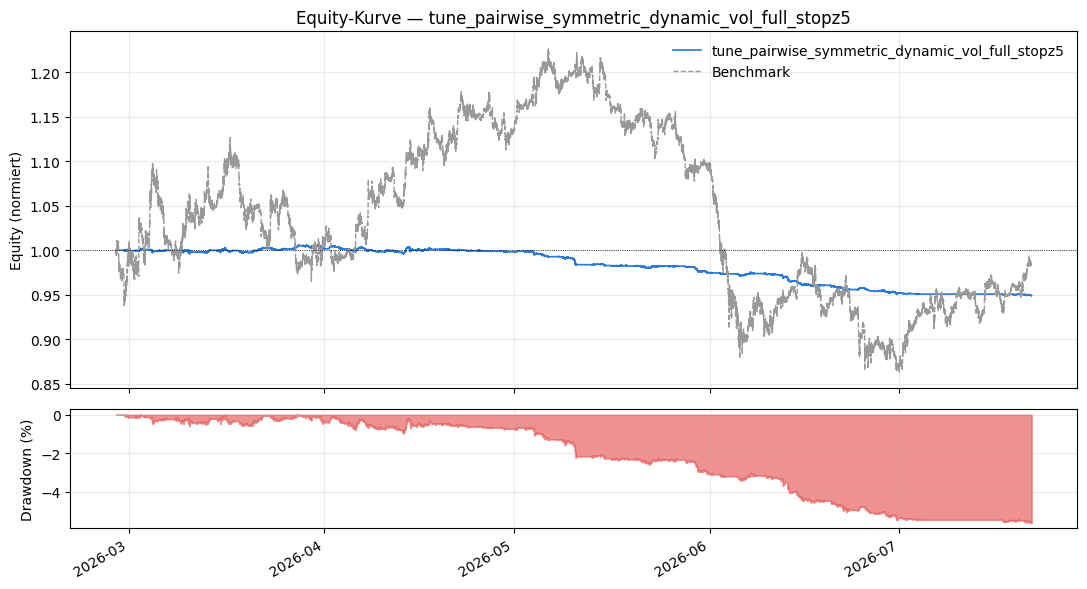

(<Figure size 1100x600 with 2 Axes>,
 (<Axes: title={'center': 'Equity-Kurve — tune_pairwise_symmetric_dynamic_vol_full_stopz5'}, ylabel='Equity (normiert)'>,
  <Axes: ylabel='Drawdown (%)'>))

In [13]:
bt_plots.plot_equity_and_drawdown(result, benchmark_close=benchmark_close)

## 9. Run speichern & mit früheren Runs vergleichen

In [14]:
run_dir = bt_runs.save_run(result)
print(f"Gespeichert: {result.run_id}")
print(run_dir)

Gespeichert: 20260817-102739_tune-pairwise-symmetric-dynamic-vol-full-stopz5_ee25696b
/Users/ryanmikus/Development/Python/00_Quant/26FS_BA/data/processed/backtests/20260817-102739_tune-pairwise-symmetric-dynamic-vol-full-stopz5_ee25696b


In [15]:
display(bt_runs.list_runs(refresh_index=True).tail(10))

,run_id,created_at,label,description,strategy_name,clique_variant,baskets,backtest_start,backtest_end,fingerprint,n_trades,sharpe_daily,cagr_daily,max_drawdown_pct,runtime_seconds
21,20260811-161145_pairwise-basket1234-topo-break...,2026-08-11T16:11:45.777566+00:00,pairwise_basket1234_topo_break_on,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,"[Basket 1, Basket 2, Basket 3, Basket 4]",2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,7b320681,217,-7.241190,-0.171392,-0.073187,59.386479
22,20260811-160944_pairwise-basket1234-topo-break...,2026-08-11T16:09:44.099375+00:00,pairwise_basket1234_topo_break_off,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,"[Basket 1, Basket 2, Basket 3, Basket 4]",2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,141682cf,212,-7.251162,-0.169602,-0.072392,34.072010
23,20260811-160539_pairwise-basket1-topo-break-on...,2026-08-11T16:05:39.281932+00:00,pairwise_basket1_topo_break_on,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,8cf8b893,76,-4.297511,-0.066698,-0.030673,19.793534
24,20260811-160444_pairwise-basket1-topo-break-of...,2026-08-11T16:04:44.391237+00:00,pairwise_basket1_topo_break_off,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,3782a41a,76,-4.297511,-0.066698,-0.030673,9.136886
25,20260811-005244_pairwise-basket1-residual-24h_...,2026-08-11T00:52:44.080658+00:00,pairwise_basket1_residual_24h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,residual_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,5b80acd7,5,-1.321198,-0.003622,-0.003639,2.249917
26,20260811-005231_pairwise-basket1-residual-12h_...,2026-08-11T00:52:31.073432+00:00,pairwise_basket1_residual_12h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,residual_12h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,5eb79671,12,-2.705278,-0.015151,-0.007469,1.218577
27,20260811-005219_pairwise-basket1-residual-6h_3...,2026-08-11T00:52:19.094698+00:00,pairwise_basket1_residual_6h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,residual_6h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,3a38b525,6,-2.359453,-0.007265,-0.004354,2.005559
28,20260811-005206_pairwise-basket1-raw-12h_73ae444b,2026-08-11T00:52:06.223666+00:00,pairwise_basket1_raw_12h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,raw_12h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,73ae444b,130,-4.562500,-0.075088,-0.036685,9.066313
29,20260811-005146_pairwise-basket1-raw-6h_6d7ff157,2026-08-11T00:51:46.243373+00:00,pairwise_basket1_raw_6h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,raw_6h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,6d7ff157,115,-4.774419,-0.076830,-0.036143,9.118448
30,20260811-004926_pairwise-basket1-baseline_f58a...,2026-08-11T00:49:26.367598+00:00,pairwise_basket1_baseline,"Baseline: PairwiseZScoreStrategy, nur Basket 1...",pairwise_zscore,raw_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,f58a3bd8,76,-4.297511,-0.066698,-0.030673,10.668369


In [16]:
# Konkrete Runs zum Vergleich eintragen, z.B. getunt vs. hand-parametrisiert:
# bt_runs.compare_runs([result.run_id, "<anderer-run-id>"])

## 10. Interpretation

_Freitext: wie stabil war `best_value` über die Trials (siehe `trials_df` in Abschnitt 5)? Wich der finale Out-of-Sample-Backtest stark von der Walk-Forward-Robustheitsschätzung ab (Overfitting-Indiz)? Welche Baskets profitierten am meisten vom Tuning gegenüber Hand-Parametern? Wie gross ist das gefundene `entry_z_delta` typischerweise (nahe 0 = Regime-Anpassung bringt kaum etwas, nahe am oberen Rand des Suchraums = evtl. Suchraum erweitern)?_

### stop_z=4.0 vs. stop_z=5.0
Nach beiden "full"-Durchgängen (`STOP_Z=4.0` und `STOP_Z=5.0`, Abschnitt 1) über `04_run_comparison.ipynb` vergleichen (`run_id`s beider `RUN_LABEL`-Varianten eintragen) — insbesondere `exit_reason_counts`/Stop-Rate und `sharpe_daily`/`total_return`. Welcher Wert führt zu weniger Stop-Exits, ohne dass die Verluste pro Stop-Trade dafür deutlich grösser werden? Die früheren schnellen 8-Trial-Läufe (`_stopz4`/`_stopz5` ohne `_full`) bewusst NICHT mehr für den Vergleich heranziehen — andere `FOLD_DAYS`/`pair_prefilter_top_n`, nicht vergleichbar.

### Nächste Schritte
- [ ] Besseren `stop_z`-Wert übernehmen (basierend auf den beiden `_full`-Läufen).
- [ ] Falls im m-Sensitivitätsvergleich (`01_pairwise_bollinger.ipynb`) ein anderes `VOL_REGIME_LOOKBACK_HOURS` als das hier eingetragene gewonnen hat: hier nachziehen und neu tunen.